# BlueShift: ocean conditions and ten priority fish groups
**Question:** how are ocean temperature and chlorophyll related to recorded fish production in the supplied Mindanao data?

**Start here:** this notebook uses the ten fish groups in the project brief. It does not select the ten largest producers. The mapping to dataset names is shown before analysis.

| Step | What we do | Which yield values? |
|---|---|---|
| 1–2. Prepare | Choose fish groups and check the file | Original data |
| 3. Check missing values | Find gaps and whether enough local history exists | Original data, including blanks |
| 4. Explore and test | Describe yield and environmental relationships | Recorded yields only |
| 5. Fill supported gaps | Use means from the same fish and province | Recorded values calculate each estimate |
| 6. Compare | Check changes after filling | Recorded and estimated yields, clearly labelled |
| 7. Summarize | State findings and limits | Results above |

**Key rule:** an estimate is not a measurement. Main statistical tests never treat filled values as recorded yields. The source CSV stays unchanged; only one completed-data CSV is exported.

## 1. Settings and terms
Run every cell in order. Settings below control the file path, random seed used for plot sampling.

| Term in code or tables | Plain meaning |
|---|---|
| Recorded yield | A value already present in the original file, including zero |
| Missing yield | A blank, not automatically zero |
| Imputed / filled yield | An estimate replacing a blank |
| Province-species history (`series`) | All dates for one fish in one province |
| `chl` | Chlorophyll concentration: an ocean-productivity proxy |
| `sst` | Sea surface temperature |
| `log_y` | log(1 + recorded yield), used for plots and regression—not imputation |
| p-value | Evidence against the test's stated no-association assumption |
| `q_BH` / q-value | A p-value adjusted for testing several relationships |
| 95% confidence interval | Uncertainty around an estimated slope under the model assumptions |

Use q < 0.05 for the stated test family. A small q-value does not mean a large effect or prove causation. `MIN_GROUP_OBSERVATIONS = 2` means every fill needs at least two recorded values from the same fish and province.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display, Markdown
DATA_PATH = Path('blueshift_dataset.csv')
OUTPUT_DIR = Path('analysis_outputs')

SEED = 42
ALPHA = 0.05
MIN_GROUP_OBSERVATIONS = 2
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 15)

def interpret(text):
    display(Markdown(text))

def adjust_pvalues(table, p='p'):
    table = table.copy()
    valid = table[p].notna()
    table.loc[valid, 'q_BH'] = multipletests(table.loc[valid, p], method='fdr_bh')[1]
    return table
versions = {m: __import__(m).__version__ for m in [
    'numpy',
    'pandas',
    'scipy',
    'statsmodels',
    'seaborn',
]}
print(platform.python_version(), versions)

3.14.2 {'numpy': '2.4.1', 'pandas': '2.3.3', 'scipy': '1.17.0', 'statsmodels': '0.14.6', 'seaborn': '0.13.2'}


## 2. Select the fish groups and check the data
**Input:** the original CSV. **Output:** selected rows plus a separate copy containing recorded yields only.

One row must represent one province, species, year and quarter. Checks stop execution if row keys repeat, another predictor is missing or a recorded yield is negative. Environmental summaries count each province-quarter once because its measurements repeat across species.

### Priority-name mapping
The brief mixes common names, scientific names and broad reporting categories. This operational mapping follows the local-name labels in [PSA fisheries tables](https://rsso04a.psa.gov.ph/sites/default/files/attachment-dir/Annex%20A%20and%20Technical%20Note_0.pdf). It does not claim exact taxonomic identification.

**Important choices:** PSA labels Frigate Tuna as Tulingan and Skipjack as Gulyasan, so the primary analysis uses Frigate Tuna rather than merging different tuna categories. PSA labels Bali Sardinella as Tamban; the generic Sardines and Fimbriated Sardines rows remain separate and are not silently merged. Caesio is the reporting proxy for Dalagang Bukid, not proof of the exact scientific species named in the brief. Groupers, snappers and Spanish mackerels are also broad categories. Milkfish and Tilapia may reflect culture and inland/brackish settings; ocean measurements can be indirect proxies, not direct habitat exposure.

The mapping table and excluded near-name coverage below make these choices visible. No categories are added together or double-counted.

In [2]:
priority_mapping = pd.DataFrame([
    ('Bangus', 'Milkfish'),
    ('Tilapia', 'Tilapia'),
    ('Galunggong', 'Roundscad'),
    ('Tulingan', 'Frigate Tuna'),
    ('Tamban', 'Bali Sardinella'),
    ('Dalagang Bukid', 'Caesio'),
    ('Lapu-Lapu', 'Grouper'),
    ('Maya-Maya', 'Snapper'),
    ('Alumahan', 'Indian Mackerel'),
    ('Tanigue', 'Spanish Mackerel'),
], columns=['Priority name', 'Dataset species'])
PRIORITY_SPECIES = priority_mapping['Dataset species'].tolist()
display(priority_mapping)


,Priority name,Dataset species
0,Bangus,Milkfish
1,Tilapia,Tilapia
2,Galunggong,Roundscad
3,Tulingan,Frigate Tuna
4,Tamban,Bali Sardinella
5,Dalagang Bukid,Caesio
6,Lapu-Lapu,Grouper
7,Maya-Maya,Snapper
8,Alumahan,Indian Mackerel
9,Tanigue,Spanish Mackerel


In [3]:
all_species_data = pd.read_csv(DATA_PATH)
assert set(PRIORITY_SPECIES).issubset(all_species_data['Species'].unique())
selected_original_data = all_species_data.loc[
    all_species_data['Species'].isin(PRIORITY_SPECIES)
].copy().reset_index(drop=True)
print(f'Selected {len(selected_original_data):,} of {len(all_species_data):,} rows: ten priority categories.')
# Use shorter internal column names; keep original columns for export.
rename = {column: column.lower() for column in selected_original_data.columns}
for column in selected_original_data.columns:
    if column.startswith('Chlorophyll'):
        rename[column] = 'chl'
    elif column.startswith('Sea Surface'):
        rename[column] = 'sst'
    elif column.startswith('Yield'):
        rename[column] = 'yield'
data = selected_original_data.rename(columns=rename).copy()
TARGET = 'yield'
# Create a quarter number and a province-species identifier.
data['quarter_n'] = data['quarter'].str.removeprefix('Q').astype(int)
data['time'] = (data.year - data.year.min()) * 4 + data.quarter_n - 1
data['series'] = data.province + ' | ' + data.species
data['missing'] = data[TARGET].isna().astype(int)
assert not data.duplicated(['year', 'quarter', 'province', 'species']).any(), 'Duplicate panel keys: inspect before continuing'
assert data[['year', 'quarter', 'province', 'species', 'chl', 'sst']].notna().all().all()
assert data.loc[data[TARGET].notna(), TARGET].ge(0).all()
# Keep the measured data separate from later estimates.
environmental_data = data.drop_duplicates(['province', 'time']).copy()
assert data.groupby(['province', 'time'])[['chl', 'sst']].nunique().max().max() == 1
recorded_data = data[data[TARGET].notna()].copy()
recorded_data['log_y'] = np.log1p(recorded_data[TARGET])
recorded_counts_by_history = data.groupby('series')[TARGET].count()
data['series_observed_n'] = data.series.map(recorded_counts_by_history)

Selected 23,040 of 152,064 rows: ten priority categories.


## 3. Understand missing yield

### 3.1 How much is missing?
A blank yield means **unknown**, not zero. Recorded zeros remain real observations. Count missing values in every column before choosing an imputation method.

In [4]:
missing_summary = pd.DataFrame({
    'Missing values': selected_original_data.isna().sum(),
    'Missing (%)': selected_original_data.isna().mean() * 100,
})
display(missing_summary.round(1))
interpret(f'**{data[TARGET].isna().sum():,} of {len(data):,} yields are missing '
          f'({data["missing"].mean():.1%}).**')

,Missing values,Missing (%)
Year,0,0.0
Quarter,0,0.0
Province,0,0.0
Species,0,0.0
Chlorophyll-A Concentration (mg/m³),0,0.0
Sea Surface Temperature (°C),0,0.0
Yield (Metric Tons),2254,9.8


**2,254 of 23,040 yields are missing (9.8%).**

### 3.2 Where are the gaps?
Compare missing percentages by year, province and species. For province and species, show the ten highest percentages. This identifies groups with poor reporting coverage.

In [5]:
def missing_by_group(column):
    counts = data.groupby(column)[TARGET].agg(total='size', observed='count')
    counts['missing'] = counts['total'] - counts['observed']
    counts['missing_pct'] = 100 * counts['missing'] / counts['total']
    return counts

for column in ['year', 'province', 'species']:
    summary = missing_by_group(column)
    if column != 'year':
        summary = summary.sort_values('missing_pct', ascending=False).head(10)
    interpret(f'**Missing yield by {column}**')
    display(summary.round(1))
interpret('**Reading these tables:** missing_pct compares missing yields with all rows in each group. '
          'High percentages identify limited data coverage, not necessarily low production. '
          'Year-to-year differences can reflect reporting changes. Province and species tables show only the ten highest percentages.')

**Missing yield by year**

,total,observed,missing,missing_pct
year,,,,
2002,480,395,85,17.7
2003,960,804,156,16.2
2004,960,823,137,14.3
2005,960,842,118,12.3
2006,960,850,110,11.5
2007,960,844,116,12.1
2008,960,848,112,11.7
2009,960,847,113,11.8
2010,960,851,109,11.4


**Missing yield by province**

,total,observed,missing,missing_pct
province,,,,
Davao Occidental,960,247,713,74.3
Dinagat Islands,960,406,554,57.7
Lanao del Sur,960,749,211,22.0
Sulu,960,762,198,20.6
Tawi-Tawi,960,769,191,19.9
Camiguin,960,867,93,9.7
South Cotabato,960,902,58,6.0
Davao del Sur,960,904,56,5.8
Maguindanao del Norte,960,924,36,3.8


**Missing yield by species**

,total,observed,missing,missing_pct
species,,,,
Milkfish,2304,1848,456,19.8
Tilapia,2304,1979,325,14.1
Caesio,2304,2008,296,12.8
Spanish Mackerel,2304,2069,235,10.2
Snapper,2304,2087,217,9.4
Bali Sardinella,2304,2142,162,7.0
Grouper,2304,2149,155,6.7
Indian Mackerel,2304,2152,152,6.6
Roundscad,2304,2175,129,5.6


**Reading these tables:** missing_pct compares missing yields with all rows in each group. High percentages identify limited data coverage, not necessarily low production. Year-to-year differences can reflect reporting changes. Province and species tables show only the ten highest percentages.

### 3.3 Which local histories support filling?
A blank between recorded yields can be estimated; a species with no recorded yield in a province has no local history to guide filling. Even one recorded value is insufficient under the two-observation rule.

Example: yields 10, 20, missing and 30 in one year imply a same-year estimate of 20 metric tons. If that year lacks two values, try the same quarter across years and then all dates, always within the same species and province. If none qualify, leave the yield blank. Do not borrow another province or fish category.

In [6]:
never_observed = data['series_observed_n'].eq(0)
insufficient_history = data['series_observed_n'].between(1, MIN_GROUP_OBSERVATIONS - 1)
eligible_gap = data[TARGET].isna() & data['series_observed_n'].ge(MIN_GROUP_OBSERVATIONS)
coverage = pd.DataFrame({
    'Category': ['Recorded yield', 'Eligible missing yield', 'No recorded yield', 'Too few recorded yields'],
    'Rows': [data[TARGET].notna().sum(), eligible_gap.sum(),
             never_observed.sum(), (data[TARGET].isna() & insufficient_history).sum()],
})
display(coverage)
interpret(f'**Support rule:** {eligible_gap.sum():,} gaps have at least two recorded values '
          'for that species in that province. Other blanks remain unresolved; '
          'neither species absence nor zero production is inferred.')

,Category,Rows
0,Recorded yield,20786
1,Eligible missing yield,2063
2,No recorded yield,96
3,Too few recorded yields,95


**Support rule:** 2,063 gaps have at least two recorded values for that species in that province. Other blanks remain unresolved; neither species absence nor zero production is inferred.

### 3.4 Coverage for each priority fish
The first table shows missing values for the ten selected fish groups. The second shows similarly named categories that were **not selected**. This prevents confusing generic Sardines with the chosen Tamban category, Bali Sardinella.

In [7]:
species_coverage = data.groupby('species')[TARGET].agg(rows='size', recorded='count')
species_coverage['missing'] = species_coverage.rows - species_coverage.recorded
species_coverage['missing_pct'] = 100 * species_coverage.missing / species_coverage.rows
species_coverage['no_history_provinces'] = (
    data.groupby(['species', 'province'])[TARGET].count().eq(0).groupby('species').sum()
)
display(species_coverage.round(2))
near_names = ['Skipjack', 'Eastern Little Tuna', 'Sardines', 'Fimbriated Sardines']
near_name_coverage = all_species_data[all_species_data.Species.isin(near_names)].groupby('Species').agg(
    rows=('Year', 'size'), recorded=('Yield (Metric Tons)', 'count')
)
display(near_name_coverage)
interpret('**Name-matching check:** the second table shows excluded near-name categories, '
          'not additional target species. Their missingness must not be substituted for the chosen PSA category. '
          'For example, generic Sardines coverage does not describe Bali Sardinella coverage.')

,rows,recorded,missing,missing_pct,no_history_provinces
species,,,,,
Bali Sardinella,2304,2142,162,7.03,0
Caesio,2304,2008,296,12.85,0
Frigate Tuna,2304,2177,127,5.51,0
Grouper,2304,2149,155,6.73,0
Indian Mackerel,2304,2152,152,6.60,0
Milkfish,2304,1848,456,19.79,0
Roundscad,2304,2175,129,5.60,0
Snapper,2304,2087,217,9.42,0
Spanish Mackerel,2304,2069,235,10.20,0


,rows,recorded
Species,,
Eastern Little Tuna,2304,1824
Fimbriated Sardines,2304,1809
Sardines,2304,51
Skipjack,2304,2115


**Name-matching check:** the second table shows excluded near-name categories, not additional target species. Their missingness must not be substituted for the chosen PSA category. For example, generic Sardines coverage does not describe Bali Sardinella coverage.

### 3.5 Is missingness associated with a group?
The chi-square test asks: **is the missing-yield proportion the same across the groups of this variable?**

- **p:** a small value suggests different missing percentages.
- **q_BH:** p adjusted for the four tests; use 0.05 as the cutoff.
- **Cramer's V:** association strength, from 0 (weak) to 1 (strong).

These are screening tests because observations repeat over time. They do not explain why yields are missing or prove that imputation is unbiased. Very small p-values may display as zero due to numerical precision.

In [8]:
def test_missingness(column):
    # Each row is a group; columns count observed and missing yields.
    counts = pd.crosstab(data[column], data['missing'])
    chi_square, p_value, degrees_freedom, expected = stats.chi2_contingency(counts)
    # Cramer's V simplifies because this table has two columns.
    strength = np.sqrt(chi_square / counts.to_numpy().sum())
    return {
        'variable': column,
        'chi_square': chi_square,
        'df': degrees_freedom,
        'p': p_value,
        'cramers_v': strength,
        'smallest_expected_count': expected.min(),
    }

missing_tests = pd.DataFrame([
    test_missingness(column)
    for column in ['year', 'quarter', 'province', 'species']
])
missing_tests = adjust_pvalues(missing_tests)
display(missing_tests)
strongest = missing_tests.sort_values('cramers_v', ascending=False).iloc[0]
interpret(f'Missingness is most strongly associated with **{strongest.variable}** '
          f'(strength = {strongest.cramers_v:.2f}). '
          'Missing values are unevenly distributed across groups. '
          'Validation on known yields may not represent missing yields.')

,variable,chi_square,df,p,cramers_v,smallest_expected_count,q_BH
0,year,314.271293,24,2.218300e-52,0.116791,46.958333,2.957733e-52
1,quarter,4.364906,3,2.246615e-01,0.013764,563.500000,2.246615e-01
2,province,8760.512675,23,0.000000e+00,0.616628,93.916667,0.000000e+00
3,species,499.546717,9,7.189184e-102,0.147247,225.400000,1.437837e-101


Missingness is most strongly associated with **province** (strength = 0.62). Missing values are unevenly distributed across groups. Validation on known yields may not represent missing yields.

### 3.6 Visual summary
Each cell is one species-province combination. Dark cells have fewer missing yields; light cells have more. A value of 1 means every yield is missing.

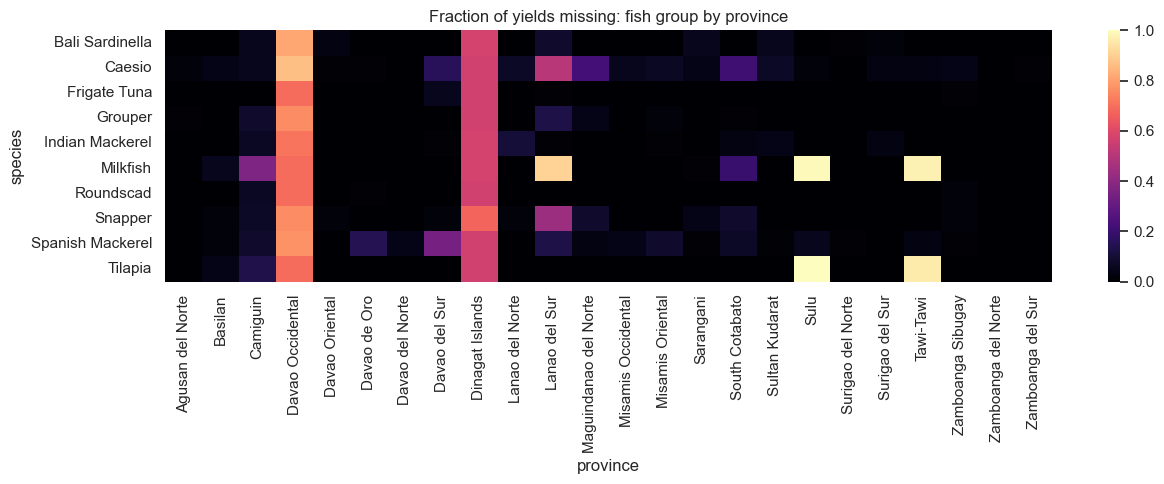

**Heatmap interpretation:** 1 combinations have every yield missing. The mix of dark and light bands shows uneven coverage across species and provinces. Light cells indicate missing information; they do not indicate zero catch.

In [9]:
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(
    data.pivot_table(index='species', columns='province', values='missing'),
    vmin=0,
    vmax=1,
    cmap='magma',
    ax=ax,
)
ax.set_title('Fraction of yields missing: fish group by province')
plt.tight_layout()
plt.show()
interpret(f'**Heatmap interpretation:** {recorded_counts_by_history.eq(0).sum()} combinations have every yield missing. '
          'The mix of dark and light bands shows uneven coverage across species and provinces. '
          'Light cells indicate missing information; they do not indicate zero catch.')

## 4. EDA: recorded data only
**No imputed yields are used in this section.** All yield summaries, plots and tests use rows with recorded yield (`recorded_data`). Environmental summaries count each province-quarter measurement once (`environmental_data`).

The order is: individual distributions, relationships between two variables, then an adjusted model with multiple predictors. Results describe associations in the available records, not causal effects or complete population production.

### 4.1 Univariate EDA: one variable at a time
#### Summary tables
The median describes a typical recorded yield. The mean is more sensitive to large yields. Environmental summaries use one measurement per province and quarter.

In [10]:
display(recorded_data[TARGET].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame('observed_yield'))
display(environmental_data[['chl', 'sst']].describe().T)

interpret(f'**Yield summary:** median = {recorded_data[TARGET].median():,.2f}, '
          f'mean = {recorded_data[TARGET].mean():,.2f}, '
          f'99th percentile = {recorded_data[TARGET].quantile(.99):,.2f} metric tons. '
          'The mean is much higher than the median, showing that a small number of large yields strongly affect averages and totals.')
interpret(f'**Environmental summary:** mean chlorophyll = {environmental_data.chl.mean():.3f} mg/m3; '
          f'mean sea temperature = {environmental_data.sst.mean():.2f} C. '
          'These describe available province-quarter conditions, not independent measurements for every species.')

,observed_yield
count,20786.000000
mean,380.746351
std,1307.176692
min,0.010000
1%,0.200000
25%,12.492500
50%,65.055000
75%,308.877500
95%,1660.572500
99%,4322.424500


,count,mean,std,min,25%,50%,75%,max
chl,2304.0,0.578815,0.427815,0.09411,0.251518,0.519027,0.733136,4.136375
sst,2304.0,29.733587,0.791915,26.41099,29.354220,29.846079,30.279936,31.696978


**Yield summary:** median = 65.06, mean = 380.75, 99th percentile = 4,322.42 metric tons. The mean is much higher than the median, showing that a small number of large yields strongly affect averages and totals.

**Environmental summary:** mean chlorophyll = 0.579 mg/m3; mean sea temperature = 29.73 C. These describe available province-quarter conditions, not independent measurements for every species.

#### Distribution tests
The normality test asks whether values follow a bell-shaped normal distribution. `q_BH` adjusts for the four tests. Skewness measures asymmetry; excess kurtosis describes tail weight. Repeated observations make the p-values diagnostic screens, so use the plots too.

In [11]:
rows = []
for name, values in [
    ('yield', recorded_data[TARGET]),
    ('log1p_yield', recorded_data.log_y),
    ('chl', environmental_data.chl),
    ('sst', environmental_data.sst),
]:
    k, p = stats.normaltest(values)
    rows.append(dict(
        variable=name,
        n=len(values),
        skew=stats.skew(values),
        excess_kurtosis=stats.kurtosis(values),
        normality_K2=k,
        p=p,
    ))
normal = adjust_pvalues(pd.DataFrame(rows))
display(normal)

rejected = normal.loc[normal.q_BH < ALPHA, 'variable'].tolist()
interpret(f'**Normality check:** departures are flagged for {", ".join(rejected) or "none"} at q < {ALPHA}. '
          'A log transformation can improve readability without making yields normally distributed. '
          'Rejection is not a reason to delete valid observations.')

,variable,n,skew,excess_kurtosis,normality_K2,p,q_BH
0,yield,20786,20.641925,705.616156,46294.102262,0.000000e+00,0.000000e+00
1,log1p_yield,20786,0.008466,-0.752192,1406.549451,3.729644e-306,7.459288e-306
2,chl,2304,2.412435,10.024873,1255.394775,2.480209e-273,3.306945e-273
3,sst,2304,-0.856367,0.956392,259.807376,3.833055e-57,3.833055e-57


**Normality check:** departures are flagged for yield, log1p_yield, chl, sst at q < 0.05. A log transformation can improve readability without making yields normally distributed. Rejection is not a reason to delete valid observations.

#### Distribution plots
The first four panels show distributions. The Q-Q plot compares recorded log yield with a normal distribution: departures from the straight line indicate non-normal shape. The quarter bar chart counts dataset rows, not production.

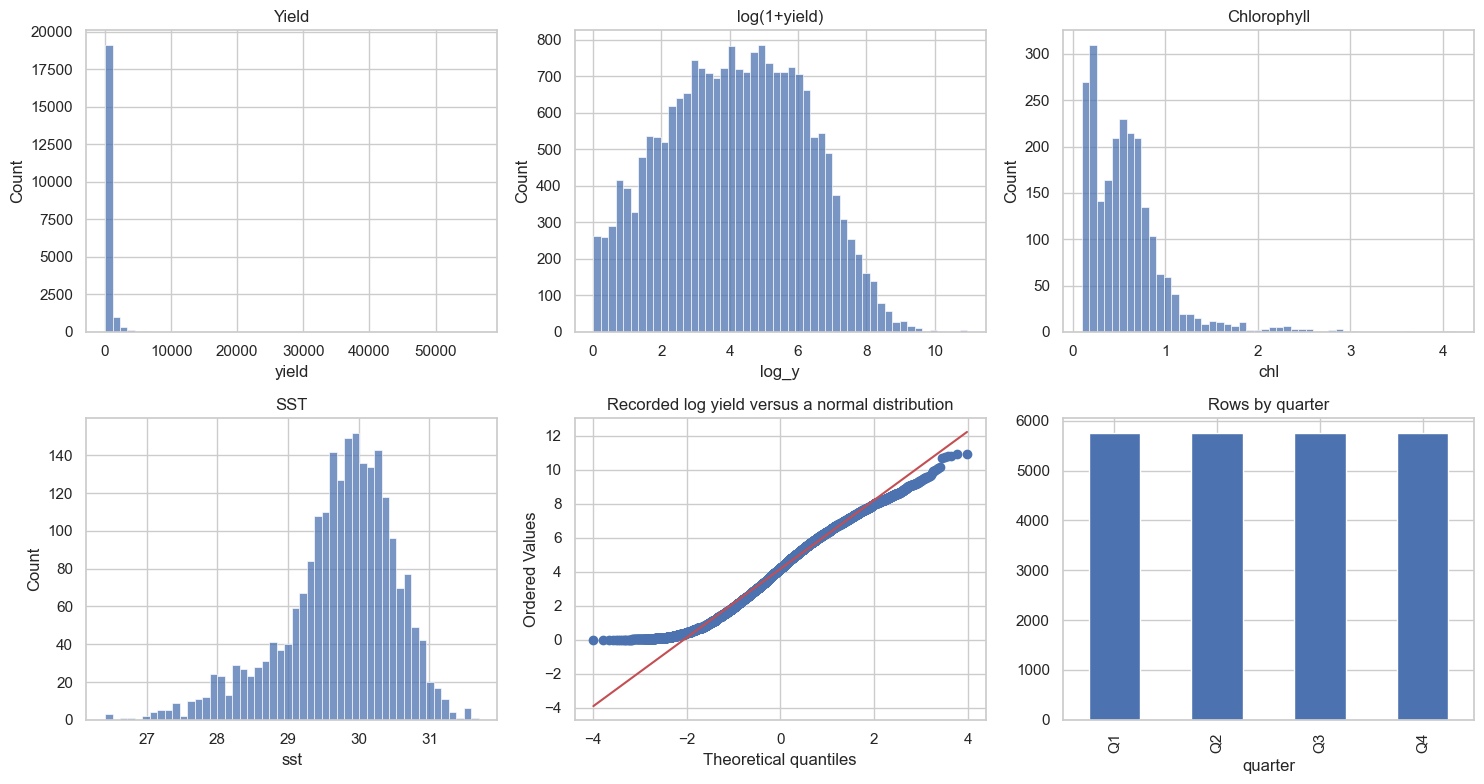

**Yield histogram:** the long right tail means most yields are relatively small, with a few very large values. **Log-yield histogram:** compressing the upper tail makes typical differences easier to see; values are now log(1 + metric tons).

**Chlorophyll histogram:** skewness = 2.41; higher values form a right tail. **Temperature histogram:** the middle 50% lies between 29.35 and 30.28 C. These plots describe conditions, not their effects on yield.

**Q-Q plot:** curved tails show that log yield still departs from a normal distribution. **Quarter counts:** equal row counts reflect the layout of the dataset; they do not establish equal yield or equal reporting completeness.

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, values) in zip(
    axes.flat,
    [
        ('Yield', recorded_data[TARGET]),
        ('log(1+yield)', recorded_data.log_y),
        ('Chlorophyll', environmental_data.chl),
        ('SST', environmental_data.sst),
    ],
):
    sns.histplot(values, bins=50, ax=ax)
    ax.set_title(name)
stats.probplot(recorded_data.log_y, plot=axes[1, 1])
axes[1, 1].set_title('Recorded log yield versus a normal distribution')
data.groupby('quarter').size().reindex(['Q1', 'Q2', 'Q3', 'Q4']).plot.bar(ax=axes[1, 2], title='Rows by quarter')
plt.tight_layout()
plt.show()

interpret('**Yield histogram:** the long right tail means most yields are relatively small, with a few very large values. '
          '**Log-yield histogram:** compressing the upper tail makes typical differences easier to see; values are now log(1 + metric tons).')
interpret(f'**Chlorophyll histogram:** skewness = {stats.skew(environmental_data.chl):.2f}; higher values form a right tail. '
          f'**Temperature histogram:** the middle 50% lies between {environmental_data.sst.quantile(.25):.2f} '
          f'and {environmental_data.sst.quantile(.75):.2f} C. '
          'These plots describe conditions, not their effects on yield.')
interpret('**Q-Q plot:** curved tails show that log yield still departs from a normal distribution. '
          '**Quarter counts:** equal row counts reflect the layout of the dataset; they do not establish equal yield or equal reporting completeness.')

### 4.2 Bivariate EDA: two variables at a time
#### Unadjusted relationship tests
Spearman correlation ranges from -1 to 1: the sign gives direction and magnitude gives strength. Kruskal-Wallis tests for distribution differences across groups. Its reported effect is an approximate epsilon-squared measure, not a correlation. Ordinary p-values assume independent rows; these are screening results.

In [13]:
rows = []
for x in ['chl', 'sst', 'year']:
    rho, p = stats.spearmanr(recorded_data[x], recorded_data[TARGET])
    rows.append(dict(predictor=x, test='Spearman (iid screen)', effect=rho, p=p))
for x in ['province', 'species', 'quarter']:
    groups = [v[TARGET].to_numpy() for _, v in recorded_data.groupby(x)]
    h, p = stats.kruskal(*groups)
    rows.append(dict(
        predictor=x,
        test='Kruskal (iid screen)',
        effect=max(0, (h - len(groups) + 1) / (len(recorded_data) - len(groups))),
        p=p,
    ))
bivariate_screen = adjust_pvalues(pd.DataFrame(rows))
display(bivariate_screen)

for _, result in bivariate_screen[bivariate_screen.test.str.startswith('Spearman')].iterrows():
    direction = 'positive' if result.effect > 0 else 'negative' if result.effect < 0 else 'zero'
    interpret(f'**{result.predictor} and yield:** Spearman rho = {result.effect:.3f} ({direction}), '
              f'q = {result.q_BH:.3g}. A small q-value can accompany a weak relationship in a large dataset.')
interpret('**Group tests:** a small Kruskal-Wallis q-value suggests that at least some groups have different yield distributions. '
          'It does not identify the differing pairs or show that the grouping variable causes the difference.')

,predictor,test,effect,p,q_BH
0,chl,Spearman (iid screen),0.079791,1.029470e-30,1.544205e-30
1,sst,Spearman (iid screen),0.047902,4.855397e-12,5.826476e-12
2,year,Spearman (iid screen),-0.080101,6.108448e-31,1.221690e-30
3,province,Kruskal (iid screen),0.218383,0.000000e+00,0.000000e+00
4,species,Kruskal (iid screen),0.291807,0.000000e+00,0.000000e+00
5,quarter,Kruskal (iid screen),0.000087,1.861349e-01,1.861349e-01


**chl and yield:** Spearman rho = 0.080 (positive), q = 1.54e-30. A small q-value can accompany a weak relationship in a large dataset.

**sst and yield:** Spearman rho = 0.048 (positive), q = 5.83e-12. A small q-value can accompany a weak relationship in a large dataset.

**year and yield:** Spearman rho = -0.080 (negative), q = 1.22e-30. A small q-value can accompany a weak relationship in a large dataset.

**Group tests:** a small Kruskal-Wallis q-value suggests that at least some groups have different yield distributions. It does not identify the differing pairs or show that the grouping variable causes the difference.

#### Relationship between the environmental variables
Use unique province-quarter records so the same environmental measurement is not counted once for every species.

In [14]:
rho, p = stats.spearmanr(environmental_data.chl, environmental_data.sst)
interpret(f'Environment-only Spearman correlation: rho={rho:.3f}, nominal p={p:.3g}; repeated provinces still induce dependence.')

interpret('**Interpretation:** the correlation describes how chlorophyll and temperature move together. '
          'It is not a yield relationship, and repeated measurements within provinces limit ordinary p-value interpretation.')

Environment-only Spearman correlation: rho=0.112, nominal p=7.64e-08; repeated provinces still induce dependence.

**Interpretation:** the correlation describes how chlorophyll and temperature move together. It is not a yield relationship, and repeated measurements within provinces limit ordinary p-value interpretation.

#### Tests allowing repeated measurements
Fit one predictor at a time and allow observations for the same province-species combination to be related over time. These tests still do not adjust for the other predictors. `r2` is the fraction of recorded log-yield variation explained by each one-predictor model.

In [15]:
rows = []
for x in ['chl', 'sst', 'year', 'province', 'species', 'quarter']:
    term = f'C({x})' if x in ['province', 'species', 'quarter'] else x
    bivariate_model = smf.ols('log_y ~ ' + term, recorded_data).fit(
        cov_type='cluster',
        cov_kwds={'groups': recorded_data.series},
        use_t=True,
    )
    w = bivariate_model.wald_test_terms(scalar=True).table.loc[term]
    rows.append(dict(predictor=x, F=float(w.statistic), p=float(w.pvalue), r2=bivariate_model.rsquared))
bivariate_tests = adjust_pvalues(pd.DataFrame(rows))
display(bivariate_tests)

significant = bivariate_tests.loc[bivariate_tests.q_BH < ALPHA, 'predictor'].tolist()
interpret(f'**Repeated-measurement tests:** {", ".join(significant) or "none"} meet q < {ALPHA}. '
          'Compare r2 with significance: a statistically detectable association may explain little variation. '
          'The adjusted model below checks whether environmental relationships remain after accounting for other predictors.')

,predictor,F,p,r2,q_BH
0,chl,0.070125,7.913846e-01,0.000143,7.913846e-01
1,sst,3.515651,6.201639e-02,0.002653,7.441967e-02
2,year,23.803058,1.954384e-06,0.006608,3.908768e-06
3,province,9.270559,3.143808e-22,0.211761,9.431423e-22
4,species,17.790491,1.876659e-22,0.284095,9.431423e-22
5,quarter,3.783568,1.113794e-02,0.000234,1.670691e-02


**Repeated-measurement tests:** year, province, species, quarter meet q < 0.05. Compare r2 with significance: a statistically detectable association may explain little variation. The adjusted model below checks whether environmental relationships remain after accounting for other predictors.

#### Relationship plots
Scatter plots show a reproducible sample of up to 7,000 recorded yields for readability. Tests use all recorded yields. Boxes show medians and the middle 50% by quarter; extreme points are hidden only in the box plot.

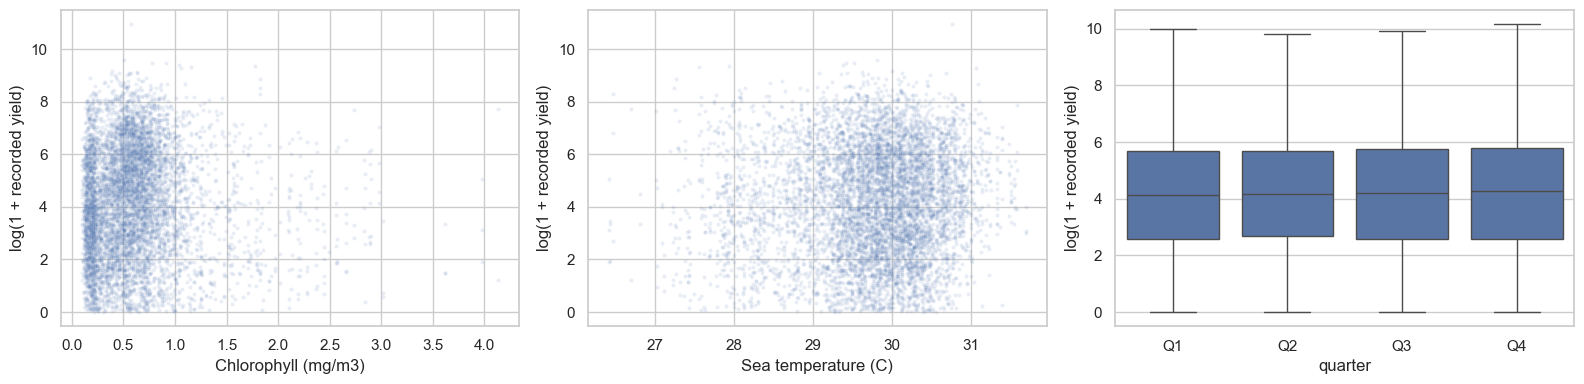

Bivariate series-clustered tests meet BH q < 0.05 for: year, province, species, quarter. These are marginal associations; differences in species, province and time composition can explain them. Rank correlation and omnibus tests do not establish causation or identify which category pairs differ.

**Scatter plots:** broad vertical spread means similar environmental conditions can accompany very different yields. These pooled plots combine species and provinces, so they cannot isolate environmental effects. **Quarter box plots:** compare median lines and box overlap; quarter differences can also reflect species mix and reporting coverage.

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sample = recorded_data.sample(min(7000, len(recorded_data)), random_state=SEED)
for ax, x in zip(axes[:2], ['chl', 'sst']):
    sns.scatterplot(data=sample, x=x, y='log_y', alpha=0.12, s=8, ax=ax)
    label = 'Chlorophyll (mg/m3)' if x == 'chl' else 'Sea temperature (C)'
    ax.set(xlabel=label, ylabel='log(1 + recorded yield)')
sns.boxplot(
    data=recorded_data,
    x='quarter',
    y='log_y',
    order=['Q1', 'Q2', 'Q3', 'Q4'],
    showfliers=False,
    ax=axes[2],
)
axes[2].set_ylabel('log(1 + recorded yield)')
plt.tight_layout()
plt.show()
sig = bivariate_tests.loc[bivariate_tests.q_BH < ALPHA, 'predictor'].tolist()
interpret(f"Bivariate series-clustered tests meet BH q < {ALPHA} for: {', '.join(sig) or 'none'}. These are marginal associations; differences in species, province and time composition can explain them. Rank correlation and omnibus tests do not establish causation or identify which category pairs differ.")
interpret('**Scatter plots:** broad vertical spread means similar environmental conditions can accompany very different yields. '
          'These pooled plots combine species and provinces, so they cannot isolate environmental effects. '
          '**Quarter box plots:** compare median lines and box overlap; quarter differences can also reflect species mix and reporting coverage.')

### 4.3 Multivariate analysis: predictors considered together
**Recorded yields only.** Model log(1 + yield) using chlorophyll, sea temperature, species, province, quarter and a linear year trend. `C(...)` marks categorical predictors. Standardized environmental predictors use one standard deviation as the unit.

Two-way clustered standard errors allow repeated province-species measurements and shared time shocks. A province-clustered model checks sensitivity to dependence across species in the same province. These corrections do not remove missingness bias or establish causation.

The model assumes common linear environmental slopes. Read confidence intervals together with the joint environmental test. Category coefficients compare groups with a reference category; omnibus tests ask whether a category's coefficients are jointly zero.

#### 4.3.1 Fit the adjusted model
Hold the included province, fish, quarter and year differences constant when estimating environmental slopes. The full coefficient table stays in memory; the next cell displays only the key slopes and joint tests.

In [17]:
for x in ['chl', 'sst']:
    mean_value = environmental_data[x].mean()
    standard_deviation = environmental_data[x].std()
    data[x + '_z'] = (data[x] - mean_value) / standard_deviation
data['year_c'] = data.year - data.year.mean()
recorded_data = data[data[TARGET].notna()].copy()
recorded_data['log_y'] = np.log1p(recorded_data[TARGET])
FORMULA = 'log_y ~ chl_z + sst_z + year_c + C(quarter) + C(province) + C(species)'
groups = np.column_stack([pd.factorize(recorded_data.series)[0], pd.factorize(recorded_data.time)[0]])
pooled_model = smf.ols(FORMULA, recorded_data).fit(cov_type='cluster', cov_kwds={'groups': groups}, use_t=True)
spatial = smf.ols(FORMULA, recorded_data).fit(
    cov_type='cluster',
    cov_kwds={'groups': recorded_data.province},
    use_t=True,
)
confidence_intervals = pooled_model.conf_int()
coefficient_table = pd.DataFrame({
    'beta': pooled_model.params,
    'SE_two_way': pooled_model.bse,
    'CI_low': confidence_intervals[0],
    'CI_high': confidence_intervals[1],
    'p': pooled_model.pvalues,
    'p_province_cluster': spatial.pvalues,
})
coefficient_table['pct_change_1plus_yield'] = 100 * np.expm1(coefficient_table.beta)

interpret(f'**Model fitted:** {int(pooled_model.nobs):,} recorded yields; R-squared = {pooled_model.rsquared:.3f}. '
          'This is the fraction of log-yield variation explained in these records, not future prediction accuracy.')

**Model fitted:** 20,786 recorded yields; R-squared = 0.508. This is the fraction of log-yield variation explained in these records, not future prediction accuracy.

#### 4.3.2 Read the test results
The joint table asks whether a group of model terms is collectively zero. The smaller coefficient table shows direction and uncertainty for chlorophyll, temperature and year. A zero-crossing interval means the sign is uncertain at that confidence level.

In [18]:
def joint_zero_test(model, names):
    """Test whether the named slopes are zero; skip invalid covariance."""
    restriction_matrix = np.eye(len(model.params))[[list(model.params.index).index(x) for x in names]]
    tested_covariance = restriction_matrix @ model.cov_params().to_numpy() @ restriction_matrix.T
    if np.linalg.matrix_rank(tested_covariance) < len(names) or np.linalg.eigvalsh(tested_covariance).min() <= 0:
        return dict(F=np.nan, p=np.nan, status='not estimable: singular/indefinite cluster covariance')
    result = model.wald_test(restriction_matrix, scalar=True)
    return dict(F=float(result.statistic), p=float(result.pvalue), status='estimable')
tests = []
for term, names in [
    ('environment', ['chl_z', 'sst_z']),
    ('year', ['year_c']),
    ('quarter', [x for x in pooled_model.params.index if x.startswith('C(quarter)')]),
    ('province', [x for x in pooled_model.params.index if x.startswith('C(province)')]),
    ('species', [x for x in pooled_model.params.index if x.startswith('C(species)')]),
]:
    tests.append(dict(term=term, **joint_zero_test(pooled_model, names)))
joint_tests = adjust_pvalues(pd.DataFrame(tests))
display(joint_tests)
environment_row = joint_tests.set_index('term').loc['environment']
interpret(f'**Joint tests:** environmental p = {environment_row.p:.3g}, q = {environment_row.q_BH:.3g}. '
          'This tests chlorophyll and temperature together after adjustment. '
          'Small group-test q-values indicate differences among category levels, not which pairs differ.')
key_coefficients = adjust_pvalues(coefficient_table.loc[['chl_z', 'sst_z', 'year_c']].copy())
display(key_coefficients)

for name, label in [('chl_z', 'Chlorophyll'), ('sst_z', 'Temperature'), ('year_c', 'Year')]:
    result = key_coefficients.loc[name]
    decision = 'meets the q < 0.05 cutoff' if result.q_BH < ALPHA else 'does not meet the q < 0.05 cutoff'
    interpret(f'**{label}:** slope {result.beta:+.3f}; 95% interval '
              f'[{result.CI_low:+.3f}, {result.CI_high:+.3f}]; q = {result.q_BH:.3g}. '
              f'This term {decision}. These are adjusted associations, not causes.')

,term,F,p,status,q_BH
0,environment,4.209313,1.771862e-02,estimable,2.214828e-02
1,year,11.099876,1.230964e-03,estimable,2.051607e-03
2,quarter,0.624890,6.006522e-01,estimable,6.006522e-01
3,province,18.460049,1.237341e-25,estimable,3.093353e-25
4,species,37.685495,1.443327e-27,estimable,7.216633e-27


**Joint tests:** environmental p = 0.0177, q = 0.0221. This tests chlorophyll and temperature together after adjustment. Small group-test q-values indicate differences among category levels, not which pairs differ.

,beta,SE_two_way,CI_low,CI_high,p,p_province_cluster,pct_change_1plus_yield,q_BH
chl_z,-0.011967,0.026290,-0.064159,0.040224,0.650003,0.731272,-1.189575,0.650003
sst_z,0.061974,0.025434,0.011481,0.112468,0.016687,0.004885,6.393503,0.025030
year_c,-0.019048,0.005717,-0.030398,-0.007698,0.001231,0.050400,-1.886759,0.003693


**Chlorophyll:** slope -0.012; 95% interval [-0.064, +0.040]; q = 0.65. This term does not meet the q < 0.05 cutoff. These are adjusted associations, not causes.

**Temperature:** slope +0.062; 95% interval [+0.011, +0.112]; q = 0.025. This term meets the q < 0.05 cutoff. These are adjusted associations, not causes.

**Year:** slope -0.019; 95% interval [-0.030, -0.008]; q = 0.00369. This term meets the q < 0.05 cutoff. These are adjusted associations, not causes.

#### 4.3.3 Check model weaknesses
VIF describes overlap among predictors. The residual plot checks whether errors have similar spread. The Q-Q plot checks their shape. These checks describe weaknesses; they do not turn an association into a causal result.

,term,VIF
0,chl_z,2.593265
1,sst_z,3.581741
2,year_c,1.241083


**Predictor overlap:** maximum VIF among the environmental and year terms is 3.58. A VIF near 1 means little inflation from overlap; larger values imply less precise individual slope estimates.

Recorded log-yield model R-squared = 0.508; n = 20,786. Breusch–Pagan nominal LM p = 0; this is a residual diagnostic with iid assumptions, not the basis for clustered inference.

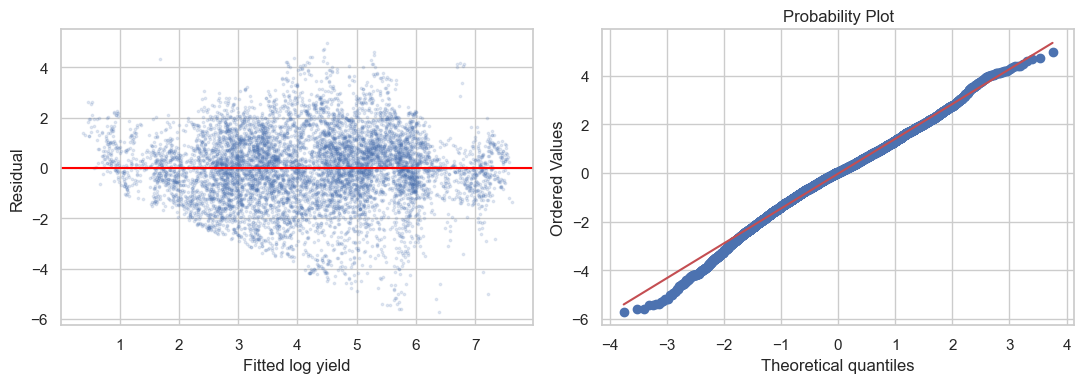

**Residual-versus-fitted plot:** the uneven, fan-like spread indicates that prediction errors do not have constant variance. **Residual Q-Q plot:** tail departures show imperfect normality. Clustered standard errors address dependence in inference, but do not fix a poorly specified model or missingness bias.

In [19]:
design_matrix = pooled_model.model.exog
vif = pd.DataFrame([{
    'term': pooled_model.model.exog_names[i],
    'VIF': variance_inflation_factor(design_matrix, i),
} for i in range(1, len(pooled_model.params)) if pooled_model.model.exog_names[i] in ['chl_z', 'sst_z', 'year_c']])
display(vif)
interpret(f'**Predictor overlap:** maximum VIF among the environmental and year terms is {vif.VIF.max():.2f}. '
          'A VIF near 1 means little inflation from overlap; larger values imply less precise individual slope estimates.')
bp = het_breuschpagan(pooled_model.resid, pooled_model.model.exog)
interpret(f'Recorded log-yield model R-squared = {pooled_model.rsquared:.3f}; n = {int(pooled_model.nobs):,}. Breusch–Pagan nominal LM p = {bp[1]:.3g}; this is a residual diagnostic with iid assumptions, not the basis for clustered inference.')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sample_indices = np.random.default_rng(SEED).choice(
    len(recorded_data),
    min(8000, len(recorded_data)),
    replace=False,
)
axes[0].scatter(pooled_model.fittedvalues.iloc[sample_indices], pooled_model.resid.iloc[sample_indices], s=3, alpha=0.15)
axes[0].axhline(0, color='red')
axes[0].set(xlabel='Fitted log yield', ylabel='Residual')
stats.probplot(pooled_model.resid.iloc[sample_indices], plot=axes[1])
plt.tight_layout()
plt.show()
interpret('**Residual-versus-fitted plot:** the uneven, fan-like spread indicates that prediction errors do not have constant variance. '
          '**Residual Q-Q plot:** tail departures show imperfect normality. '
          'Clustered standard errors address dependence in inference, but do not fix a poorly specified model or missingness bias.')

### 4.4 Priority-species associations and trends
The correlation score is computed separately for each selected species using recorded provincial-quarter yields. Spearman p-values are only descriptive screens because observations repeat. Adjusted models include province, quarter and year, with two-way clustering by province and time. BH correction covers all 20 environmental slope tests; joint-test q-values cover the ten species tests.

Rank by association, not causal impact. Milkfish and Tilapia include contexts for which ocean measurements can be indirect proxies. Broad reporting labels do not identify a precise biological species or capture versus aquaculture production.

Only environmental-coefficient uncertainty is reported for each species. Some nuisance-effect variances in two-way covariance can be invalid; they are not interpreted. An invalid environmental variance or joint-test covariance is marked unavailable rather than forced into a significance result.

#### 4.4.1 Calculate a score for each fish
For each fish, fit the same adjusted model. `rho` is the simple correlation; `beta` is the adjusted slope. They answer different questions. Read the q-values and intervals rather than comparing raw p-values across many tests.

In [20]:
def environmental_slope(model, term):
    """Return one environmental slope and its clustered uncertainty, if valid."""
    beta = model.params[term]
    variance = model.cov_params().loc[term, term]
    if not np.isfinite(variance) or variance <= 0:
        return dict(beta=beta, CI_low=np.nan, CI_high=np.nan, p=np.nan)

    standard_error = np.sqrt(variance)
    degrees_freedom = model.df_resid_inference
    critical_value = stats.t.ppf(0.975, degrees_freedom)
    p_value = 2 * stats.t.sf(abs(beta / standard_error), degrees_freedom)
    return dict(
        beta=beta,
        CI_low=beta - critical_value * standard_error,
        CI_high=beta + critical_value * standard_error,
        p=p_value,
    )

species_rows = []
for species, rows in recorded_data.groupby('species'):
    groups = np.column_stack([pd.factorize(rows.province)[0], pd.factorize(rows.time)[0]])
    model = smf.ols('log_y ~ chl_z + sst_z + year_c + C(quarter) + C(province)', rows).fit(
        cov_type='cluster', cov_kwds={'groups': groups}, use_t=True)
    joint = joint_zero_test(model, ['chl_z', 'sst_z'])
    for variable in ['chl', 'sst']:
        term = variable + '_z'
        rho, screen_p = stats.spearmanr(rows[variable], rows[TARGET])
        species_rows.append(dict(
            species=species, variable=variable, n=len(rows),
            rho=rho, screen_p=screen_p,
            **environmental_slope(model, term),
            joint_p=joint['p'], joint_status=joint['status'],
        ))
species_associations = adjust_pvalues(pd.DataFrame(species_rows))
display(species_associations[['species','variable','n','rho','beta','CI_low','CI_high','p','q_BH']].round(5))
species_joint = adjust_pvalues(species_associations.drop_duplicates('species')[
    ['species','joint_p','joint_status']].rename(columns={'joint_p':'p'}))
display(species_joint)
significant_species = species_joint.loc[species_joint.q_BH < ALPHA, 'species'].tolist()
interpret(f'**Per-species adjusted joint tests:** {", ".join(significant_species) or "none"} meet q < {ALPHA}. '
          'Compare effect sizes, intervals, coverage and habitat relevance; a small p-value is not evidence '
          'that an environmental change caused production loss.')

,species,variable,n,rho,beta,CI_low,CI_high,p,q_BH
0,Bali Sardinella,chl,2142,0.27416,-0.03461,-0.13414,0.06491,0.47910,0.73708
1,Bali Sardinella,sst,2142,-0.09059,-0.02006,-0.11999,0.07987,0.68174,0.93279
2,Caesio,chl,2008,-0.00846,-0.04313,-0.12696,0.04070,0.29826,0.59652
3,Caesio,sst,2008,0.13335,0.10414,0.03276,0.17552,0.00612,0.04083
4,Frigate Tuna,chl,2177,-0.03032,0.05383,-0.06973,0.17740,0.37681,0.62801
5,Frigate Tuna,sst,2177,-0.13569,0.00619,-0.08502,0.09741,0.88951,0.94869
6,Grouper,chl,2149,0.02012,-0.01960,-0.13550,0.09629,0.72962,0.93279
7,Grouper,sst,2149,0.10499,0.06392,-0.01819,0.14603,0.12097,0.34563
8,Indian Mackerel,chl,2152,0.10835,0.01562,-0.12049,0.15173,0.81443,0.94869
9,Indian Mackerel,sst,2152,-0.01042,0.06393,-0.04561,0.17347,0.23960,0.55220


,species,p,joint_status,q_BH
0,Bali Sardinella,0.697862,estimable,0.697862
2,Caesio,0.014571,estimable,0.072856
4,Frigate Tuna,0.641089,estimable,0.697862
6,Grouper,0.277647,estimable,0.462745
8,Indian Mackerel,0.493129,estimable,0.619262
10,Milkfish,0.084355,estimable,0.281184
12,Roundscad,0.495409,estimable,0.619262
14,Snapper,0.125037,estimable,0.312591
16,Spanish Mackerel,0.203388,estimable,0.406776
18,Tilapia,0.014564,estimable,0.072856


**Per-species adjusted joint tests:** none meet q < 0.05. Compare effect sizes, intervals, coverage and habitat relevance; a small p-value is not evidence that an environmental change caused production loss.

#### 4.4.2 Compare slopes visually
A dot gives the adjusted slope; a horizontal bar gives its 95% interval. The vertical line is zero. Longer bars mean more uncertainty. These intervals are not adjusted for multiple tests; the q-values above are.

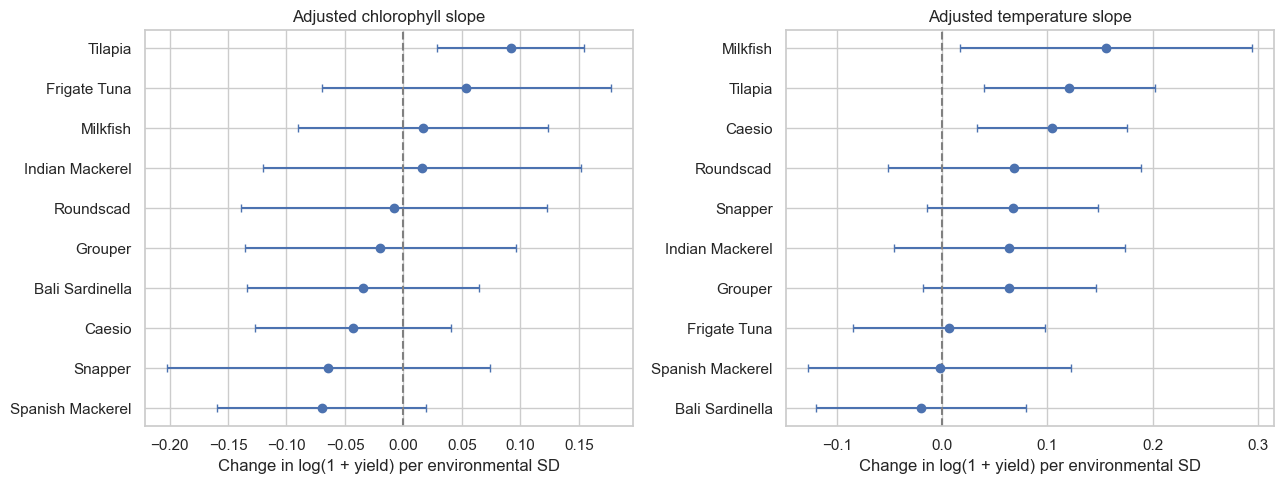

**Coefficient plots:** points are adjusted slopes, bars are 95% clustered intervals. Intervals crossing zero indicate uncertain signs. These intervals are not multiplicity-adjusted; use q-values for the family of tests. Comparisons are within recorded data, not a causal ranking.

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, variable in zip(axes, ['chl','sst']):
    values = species_associations[species_associations.variable.eq(variable)].sort_values('beta')
    lower = np.maximum(0, values.beta - values.CI_low)
    upper = np.maximum(0, values.CI_high - values.beta)
    ax.errorbar(values.beta, values.species, xerr=[lower, upper], fmt='o', capsize=3)
    ax.axvline(0, color='grey', linestyle='--')
    ax.set(title=('Adjusted chlorophyll slope' if variable == 'chl' else 'Adjusted temperature slope'), xlabel='Change in log(1 + yield) per environmental SD')
plt.tight_layout(); plt.show()
interpret('**Coefficient plots:** points are adjusted slopes, bars are 95% clustered intervals. '
          'Intervals crossing zero indicate uncertain signs. These intervals are not multiplicity-adjusted; '
          'use q-values for the family of tests. Comparisons are within recorded data, not a causal ranking.')

#### 4.4.3 Describe ocean trends
The table estimates yearly change after accounting for province and quarter. The plots show annual mean measurements; they are not species-level exposure measurements.

,variable,slope_per_year,CI_low,CI_high,p,q_BH
0,chl,0.003468,0.000998,0.005938,7.980632e-03,7.980632e-03
1,sst,0.025076,0.024110,0.026041,1.097868e-25,2.195736e-25


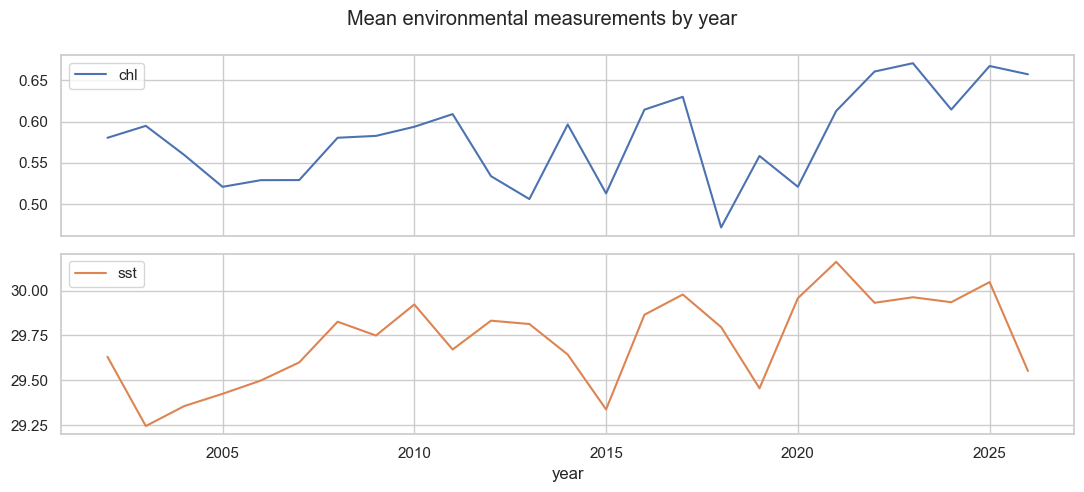

**Ocean trend plots:** annual means summarize the supplied province-quarter measurements. The trend tests adjust for quarter and province, with province-clustered uncertainty. Partial boundary years affect plotted annual means; trends do not validate the satellite extraction footprint.

In [22]:
# Environmental trends use unique province-quarter records, not repeated species rows.
trend_rows = []
for variable in ['chl','sst']:
    trend = smf.ols(f'{variable} ~ year + C(quarter) + C(province)', environmental_data).fit(
        cov_type='cluster', cov_kwds={'groups':environmental_data.province}, use_t=True)
    confidence_intervals = trend.conf_int().loc['year']
    trend_rows.append(dict(variable=variable, slope_per_year=trend.params['year'],
        CI_low=confidence_intervals.iloc[0], CI_high=confidence_intervals.iloc[1], p=trend.pvalues['year']))
environment_trends = adjust_pvalues(pd.DataFrame(trend_rows))
display(environment_trends)
environmental_data.groupby('year')[['chl','sst']].mean().plot(
    subplots=True, figsize=(11,5), title='Mean environmental measurements by year')
plt.tight_layout(); plt.show()
interpret('**Ocean trend plots:** annual means summarize the supplied province-quarter measurements. '
          'The trend tests adjust for quarter and province, with province-clustered uncertainty. '
          'Partial boundary years affect plotted annual means; trends do not validate the satellite extraction footprint.')

#### 4.4.4 Describe recorded production trends
Each panel is a different fish group. Compare years within a panel and check reporting coverage. The y-axis scales differ; boundary years have only two quarters.

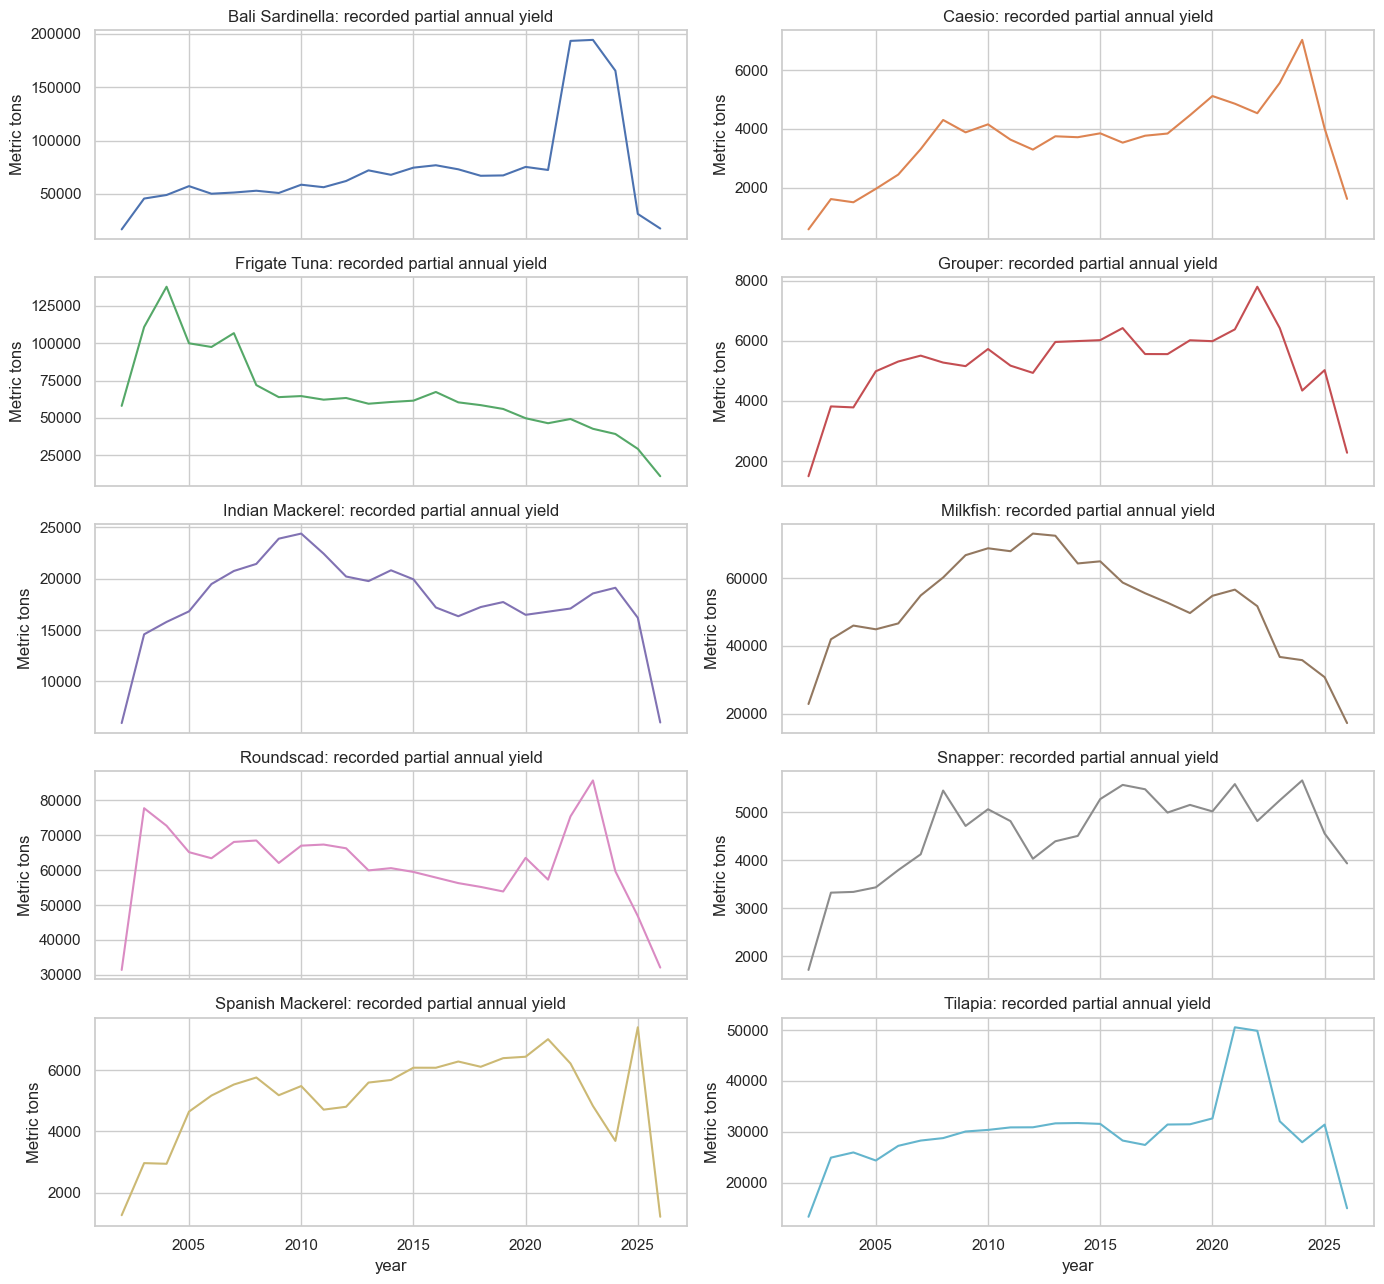

**Species production plots:** totals include recorded yields only. Drops can reflect missing reporting rather than lower production; compare species coverage before interpreting. Boundary years have two quarters. Do not interpret these as complete stock abundance trends.

In [23]:
annual_species = recorded_data.groupby(['species','year'])[TARGET].sum().unstack('species')
annual_species.plot(subplots=True, layout=(5,2), figsize=(14,13), legend=False,
                    title=[f'{s}: recorded partial annual yield' for s in annual_species.columns])
for axis in plt.gcf().axes:
    axis.set_ylabel('Metric tons')
plt.tight_layout()
plt.show()
interpret('**Species production plots:** totals include recorded yields only. Drops can reflect missing '
          'reporting rather than lower production; compare species coverage before interpreting. '
          'Boundary years have two quarters. Do not interpret these as complete stock abundance trends.')

## 5. Fill missing yield using group means
Group mean is the selected method. This section applies it directly; method comparisons and repeated hiding experiments have been removed.

Use the first group with at least two recorded yields:
1. Same fish, province and year: average other quarters.
2. Same fish, province and quarter: average other years.
3. Same fish and province: average all recorded dates.
4. Otherwise, leave the yield blank.

Never borrow another fish or province, and never reuse filled values in a mean. Later records can help fill historical gaps, so this is historical data completion, not future forecasting. Main EDA remains based on recorded yields only.

### 5.1 Calculate supported group means

In [24]:
def group_mean_details(train, target):
    """Fill only from the same province-species history; keep support and source."""
    result = pd.DataFrame(index=target.index)
    result['prediction'] = np.nan
    result['group'] = ''
    result['support_n'] = 0
    rules = [
        (['province', 'species', 'year'], 'same_year'),
        (['province', 'species', 'quarter'], 'same_quarter_other_years'),
        (['province', 'species'], 'local_species_history'),
    ]
    for columns, label in rules:
        summary = train.groupby(columns)[TARGET].agg(group_mean='mean', group_n='count')
        available = target.join(summary, on=columns)
        use = result.prediction.isna() & available.group_n.ge(MIN_GROUP_OBSERVATIONS)
        result.loc[use, 'prediction'] = available.loc[use, 'group_mean']
        result.loc[use, 'group'] = label
        result.loc[use, 'support_n'] = available.loc[use, 'group_n'].astype(int)
    return result

### 5.2 Fill supported gaps and export
Apply the selected rules once. Each estimate records its source group and number of recorded supporting values. Original measurements are preserved. This is the only cell that writes an output file.

In [25]:
missing_rows = data.loc[data[TARGET].isna()]
fill_details = group_mean_details(recorded_data, missing_rows)
completed = selected_original_data.copy()
completed['yield_completed'] = data[TARGET]
completed['yield_was_imputed'] = False
completed['imputation_method'] = ''
completed['imputation_group'] = ''
completed['imputation_support_n'] = 0
eligible = pd.Series(False, index=data.index)
filled_rows = fill_details.index[fill_details['prediction'].notna()]
eligible.loc[filled_rows] = True
completed.loc[eligible, 'yield_completed'] = fill_details.loc[filled_rows, 'prediction']
completed.loc[eligible, 'yield_was_imputed'] = True
completed.loc[eligible, 'imputation_method'] = 'group_mean'
completed.loc[eligible, 'imputation_group'] = fill_details.loc[filled_rows, 'group']
completed.loc[eligible, 'imputation_support_n'] = fill_details.loc[filled_rows, 'support_n']
completed['yield_status'] = 'recorded'
completed.loc[data[TARGET].isna(), 'yield_status'] = 'unresolved_insufficient_history'
completed.loc[data[TARGET].isna() & data.series_observed_n.eq(0), 'yield_status'] = 'unresolved_no_local_history'
completed.loc[eligible, 'yield_status'] = 'imputed'
assert completed.loc[data[TARGET].notna(), 'yield_completed'].equals(data.loc[data[TARGET].notna(), TARGET])
assert completed.loc[eligible, 'imputation_support_n'].ge(MIN_GROUP_OBSERVATIONS).all()
completion_by_species = completed.groupby('Species').agg(
    recorded=('yield_status', lambda s: s.eq('recorded').sum()),
    filled=('yield_was_imputed', 'sum'),
    unresolved=('yield_completed', lambda s: s.isna().sum()),
)
display(completion_by_species)
display(completed.loc[eligible, 'imputation_group'].value_counts().to_frame('Filled rows'))
OUTPUT_DIR.mkdir(exist_ok=True)
completed.to_csv(OUTPUT_DIR / 'blueshift_yield_completed.csv', index=False)
interpret(f'**Export:** {len(completed):,} selected-species rows; {eligible.sum():,} fills; '
          f'{completed.yield_completed.isna().sum():,} unresolved. Each fill records its group and support count. '
          'No unsupported suggestion column is supplied, and all original measurements are retained.')

,recorded,filled,unresolved
Species,,,
Bali Sardinella,2142,162,0
Caesio,2008,296,0
Frigate Tuna,2177,127,0
Grouper,2149,155,0
Indian Mackerel,2152,152,0
Milkfish,1848,361,95
Roundscad,2175,129,0
Snapper,2087,217,0
Spanish Mackerel,2069,235,0


,Filled rows
imputation_group,
same_quarter_other_years,1627
same_year,255
local_species_history,181


**Export:** 23,040 selected-species rows; 2,063 fills; 191 unresolved. Each fill records its group and support count. No unsupported suggestion column is supplied, and all original measurements are retained.

## 6. After-imputation comparison: recorded versus completed data
**This section uses estimated yields.** It is separate from the recorded-data EDA. Compare model coefficients before and after filling, then decrease or increase only filled values by 25%.

The scenarios are assumptions, not confidence intervals. Filled values are not new measurements, so they are not used to claim stronger statistical evidence. Annual totals exclude combinations still left blank. The first and last years have only part-year coverage, so their totals are not directly comparable with full years.

### 6.1 Do the model slopes change?
Compare recorded-only slopes with slopes after filling. The minus/plus 25% scenarios change estimated values only. This is a sensitivity check, not a new significance test.

In [26]:
sensitivity = []
for label, factor in [
    ('observed_only', None),
    ('completed', 1),
    ('imputed_minus25', 0.75),
    ('imputed_plus25', 1.25),
]:
    if factor is None:
        model = pooled_model
    else:
        temp = data.copy()
        temp[TARGET] = completed.yield_completed
        temp.loc[eligible, TARGET] *= factor
        temp = temp[temp[TARGET].notna()].copy()
        temp['log_y'] = np.log1p(temp[TARGET])
        model = smf.ols(FORMULA, temp).fit()
    sensitivity.append(dict(
        scenario=label,
        n=int(model.nobs),
        **model.params[['chl_z', 'sst_z', 'year_c']].to_dict(),
    ))
sensitivity_table = pd.DataFrame(sensitivity)
display(sensitivity_table)
recorded_coefficients = sensitivity_table.set_index('scenario').loc['observed_only']
completed_coefficients = sensitivity_table.set_index('scenario').loc['completed']
for term in ['chl_z', 'sst_z', 'year_c']:
    interpret(f'**{term}:** coefficient changes from {recorded_coefficients[term]:.4f} using recorded yields '
              f'to {completed_coefficients[term]:.4f} after filling. '
              'These are changes in point estimates, not new significance tests.')

,scenario,n,chl_z,sst_z,year_c
0,observed_only,20786,-0.011967,0.061974,-0.019048
1,completed,22849,-0.007343,0.058178,-0.018774
2,imputed_minus25,22849,-0.008951,0.057842,-0.017679
3,imputed_plus25,22849,-0.006084,0.058448,-0.019643


**chl_z:** coefficient changes from -0.0120 using recorded yields to -0.0073 after filling. These are changes in point estimates, not new significance tests.

**sst_z:** coefficient changes from 0.0620 using recorded yields to 0.0582 after filling. These are changes in point estimates, not new significance tests.

**year_c:** coefficient changes from -0.0190 using recorded yields to -0.0188 after filling. These are changes in point estimates, not new significance tests.

### 6.2 How do partial annual totals change?
The gap between lines is yield added by imputation. It is not measured growth. Totals still exclude unresolved yields.

,observed_sum,completed_partial_sum,unresolved_rows
year,,,
2002,153500.80,160231.327890,4
2003,327536.92,336990.818253,8
2004,358951.53,367552.183047,8
2005,323571.45,332057.385861,8
2006,321223.90,329489.184515,8
2007,348592.69,357288.127772,8
2008,324685.33,333286.184006,8
2009,316556.91,325154.777340,8
2010,334291.95,342771.250673,8


**Annual totals table:** 191 yields remain unfilled across all years. The completed total adds eligible estimates to recorded production, but is still incomplete. The difference between columns is estimated yield, not measured production growth.

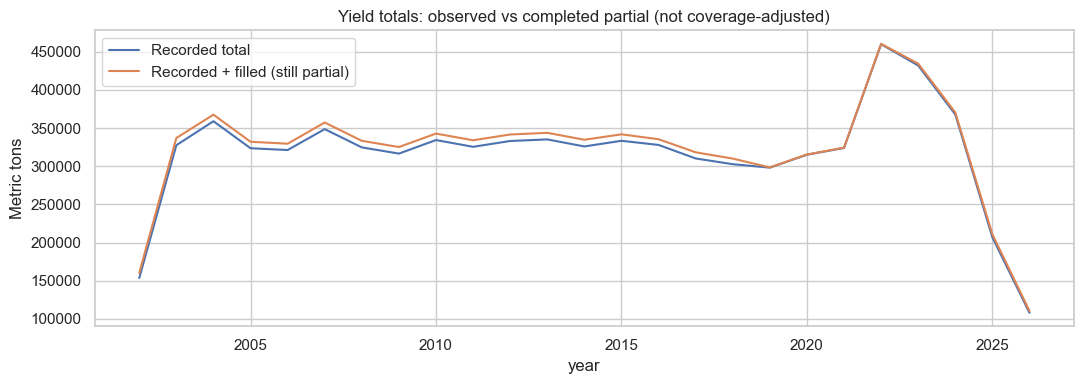

**Practical conclusion:** use the retained group-mean rule for supported retrospective gaps, retain provenance flags, and resolve the meaning of never-reported combinations before completing them. Use observed-data clustered estimates as conditional associations; inspect coefficient sensitivity before drawing substantive conclusions. Neither single imputation nor strong predictive performance establishes MAR, causal environmental effects, or complete population totals.

**Annual trend plot:** the gap between lines is the amount added by imputation. A larger completed total is expected when nonnegative estimates replace blanks. It does not prove that production increased. Partial boundary years, reporting changes and unresolved yields limit trend comparisons.

In [27]:
annual = pd.DataFrame({
    'year': data.year,
    'observed': data[TARGET],
    'completed_partial': completed.yield_completed,
    'unresolved': completed.yield_completed.isna().astype(int),
}).groupby('year').agg(observed_sum=('observed', 'sum'), completed_partial_sum=('completed_partial', 'sum'), unresolved_rows=('unresolved', 'sum'))
display(annual)
interpret(f'**Annual totals table:** {annual.unresolved_rows.sum():,} yields remain unfilled across all years. '
          'The completed total adds eligible estimates to recorded production, but is still incomplete. '
          'The difference between columns is estimated yield, not measured production growth.')
annual[['observed_sum', 'completed_partial_sum']].plot(
    figsize=(11, 4),
    title='Yield totals: observed vs completed partial (not coverage-adjusted)',
)
plt.legend(['Recorded total', 'Recorded + filled (still partial)'])
plt.ylabel('Metric tons')
plt.tight_layout()
plt.show()
interpret('**Practical conclusion:** use the retained group-mean rule for supported retrospective gaps, retain provenance flags, and resolve the meaning of never-reported combinations before completing them. Use observed-data clustered estimates as conditional associations; inspect coefficient sensitivity before drawing substantive conclusions. Neither single imputation nor strong predictive performance establishes MAR, causal environmental effects, or complete population totals.')
interpret('**Annual trend plot:** the gap between lines is the amount added by imputation. '
          'A larger completed total is expected when nonnegative estimates replace blanks. '
          'It does not prove that production increased. Partial boundary years, reporting changes and unresolved yields limit trend comparisons.')

## 7. Main findings and limits

In [28]:
interpret(f'**Selected scope:** ten PSA categories mapped to the brief; {len(data):,} rows. '
          'This is a priority list, not a production ranking or a complete species inventory.')
environment_test = joint_tests.set_index('term').loc['environment']
interpret(f'**Pooled adjusted environmental test:** p = {environment_test.p:.3g}, q = {environment_test.q_BH:.3g}. '
          'Use the per-species table for heterogeneous associations; neither analysis establishes causation.')
interpret(f'**Filling:** {eligible.sum():,} supported local gaps filled; '
          f'{completed.yield_completed.isna().sum():,} remain blank. '
          'Annual totals are partial. Association strength does not identify which fish is causally affected most.')
interpret('**Deployment limit:** no 2026 Q4 forecast is produced. Forecasting requires future environmental '
          'inputs or justified scenarios and forward-in-time validation. Imports, food availability and '
          'fishing effort are absent; food-security and import-dependence effects cannot be quantified here.')

**Selected scope:** ten PSA categories mapped to the brief; 23,040 rows. This is a priority list, not a production ranking or a complete species inventory.

**Pooled adjusted environmental test:** p = 0.0177, q = 0.0221. Use the per-species table for heterogeneous associations; neither analysis establishes causation.

**Filling:** 2,063 supported local gaps filled; 191 remain blank. Annual totals are partial. Association strength does not identify which fish is causally affected most.

**Deployment limit:** no 2026 Q4 forecast is produced. Forecasting requires future environmental inputs or justified scenarios and forward-in-time validation. Imports, food availability and fishing effort are absent; food-security and import-dependence effects cannot be quantified here.

## Reuse and references
Run in order. Edit the explicit priority mapping only when changing the study categories; do not silently merge near-name categories. The only export is `analysis_outputs/blueshift_yield_completed.csv`, now containing the selected ten categories rather than the earlier 66-category scope.

Columns include original measurements, completed yield, fill flag, status, method, source group and recorded support count. Unsupported local histories remain blank. No future-quarter prediction file is generated.

Sources: the user-provided BlueShift project brief (scope and objectives); [PSA common-name reporting categories](https://rsso04a.psa.gov.ph/sites/default/files/attachment-dir/Annex%20A%20and%20Technical%20Note_0.pdf); [PSA fisheries statistics](https://psa.gov.ph/system/files/main-publication/Fisheries%2520Statistics%2520of%2520the%2520Philippines%252C%25202019-2021_0.pdf?vcode=GW2I); [statsmodels joint tests](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.wald_test_terms.html). Dataset satellite provenance, subsectors and geographic footprints cannot be independently verified from its seven columns.